# 01 — Toy Knowledge Distillation (scikit-learn)
**Goal:** train a big *teacher* model, then train a small *student* two ways and compare:
- **student-hard**: learns only from the true labels (0/1/2...).
- **student-soft**: learns from the teacher's *probabilities* (its "hunches"), the core idea of Hinton, Vinyals & Dean (2015), building on Buciluǎ, Caruana & Niculescu-Mizil (2006, *Model compression*).

Bucila et al.'s trick: the teacher can label **extra unlabeled data**, so the student gets far more training examples than the small labeled set. We do that too.

Run cells top to bottom (Shift+Enter). Seeds are fixed so results are repeatable.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
SEED = 0

## 1. Data
A synthetic 5-class problem, split into:
- a **small labeled** training set (2,000 rows), which both models get with true labels,
- a large **unlabeled** pool (20,000 rows), labels thrown away; only the teacher may label it,
- a **test** set (5,000 rows), never used for training.

In [2]:
X, y = make_classification(n_samples=27000, n_features=20, n_informative=12,
                           n_classes=5, n_clusters_per_class=2, class_sep=1.0, random_state=SEED)
X_lab, X_rest, y_lab, y_rest = train_test_split(X, y, train_size=2000, random_state=SEED, stratify=y)
X_unl, X_test, _, y_test = train_test_split(X_rest, y_rest, test_size=5000, random_state=SEED)
print(X_lab.shape, X_unl.shape, X_test.shape)

(2000, 20) (20000, 20) (5000, 20)


## 2. Teacher: a big random forest (500 trees, unlimited depth)

In [3]:
teacher = RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1).fit(X_lab, y_lab)
acc_teacher = (teacher.predict(X_test) == y_test).mean()
print(f"Teacher accuracy: {acc_teacher:.3f}")

Teacher accuracy: 0.786


## 3. Student A: hard labels
A small decision tree (max depth 8, tiny vs. 500 deep trees) trained on the 2,000 true labels only.

In [4]:
DEPTH = 8
student_hard = DecisionTreeClassifier(max_depth=DEPTH, random_state=SEED).fit(X_lab, y_lab)
acc_hard = (student_hard.predict(X_test) == y_test).mean()
print(f"Student (hard labels) accuracy: {acc_hard:.3f}")

Student (hard labels) accuracy: 0.549


## 4. Student B: soft labels from the teacher
The teacher outputs a probability for each class on labeled + unlabeled data (22,000 rows). The *same size* tree is trained as a **regressor** to predict that whole probability vector; we then pick the class with the highest predicted probability.

In [5]:
X_transfer = np.vstack([X_lab, X_unl])
soft = teacher.predict_proba(X_transfer)          # shape (22000, 5), rows sum to 1
print("example teacher hunch:", soft[0].round(2))
student_soft = DecisionTreeRegressor(max_depth=DEPTH, random_state=SEED).fit(X_transfer, soft)
acc_soft = (student_soft.predict(X_test).argmax(1) == y_test).mean()
print(f"Student (soft labels) accuracy: {acc_soft:.3f}")

example teacher hunch: [0.15 0.01 0.77 0.03 0.03]


Student (soft labels) accuracy: 0.614


### Control: is it the soft labels, or just the extra data?
Train the same tree on the teacher's *hard* guesses (argmax) over the same 22,000 rows. If soft ≈ this, most of the gain came from the extra teacher-labeled data (Bucila's point); if soft is higher, the hunches themselves helped (Hinton's point).

In [6]:
student_teacher_hard = DecisionTreeClassifier(max_depth=DEPTH, random_state=SEED).fit(X_transfer, soft.argmax(1))
acc_th = (student_teacher_hard.predict(X_test) == y_test).mean()
print(f"Student (teacher's hard guesses, extra data): {acc_th:.3f}")

Student (teacher's hard guesses, extra data): 0.623


## 5. Results

Teacher (500 trees)                    0.786
Student hard (true labels)             0.549
Student teacher-hard (+extra data)     0.623
Student soft (+extra data)             0.614


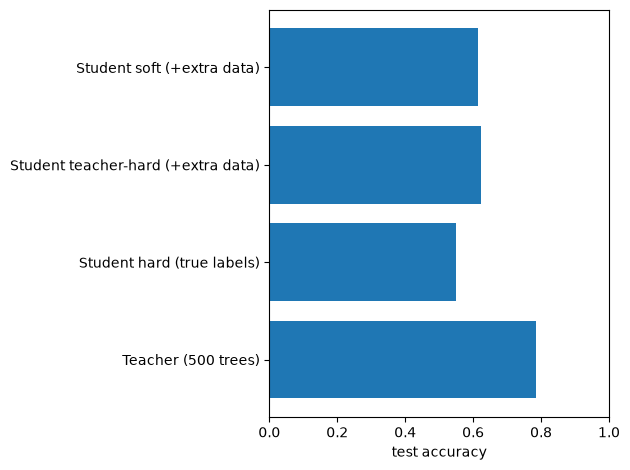

In [7]:
res = {"Teacher (500 trees)": acc_teacher, "Student hard (true labels)": acc_hard,
       "Student teacher-hard (+extra data)": acc_th, "Student soft (+extra data)": acc_soft}
for k,v in res.items(): print(f"{k:38s} {v:.3f}")
plt.barh(list(res), list(res.values())); plt.xlim(0,1); plt.xlabel("test accuracy"); plt.tight_layout(); plt.show()

**Reading it honestly:** the numbers above are what happened; nothing is tuned to make soft win. A random forest's probabilities are fairly coarse (vote fractions), so the soft-vs-teacher-hard gap is often small; the bigger lever in this toy is usually the extra teacher-labeled data. With neural nets (step 02) soft targets carry richer information, which is where Hinton's temperature trick matters.

## 6. Temperature demo
A neural net produces *logits* z; softmax with temperature T is p_i = exp(z_i/T) / Σ exp(z_j/T). Higher T flattens the distribution so small "this looks a bit like a 3" hunches become visible to the student.

T=1: [0.971 0.018 0.007 0.004 0.001]
T=2: [0.762 0.103 0.063 0.049 0.023]
T=5: [0.417 0.187 0.153 0.139 0.103]


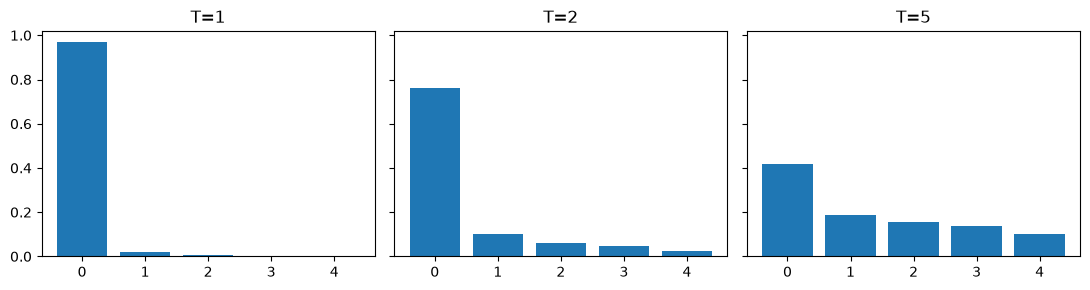

In [8]:
def softmax(z, T): e = np.exp((z - z.max())/T); return e/e.sum()
z = np.array([6.0, 2.0, 1.0, 0.5, -1.0])   # made-up logits for 5 classes
fig, ax = plt.subplots(1,3, figsize=(11,3), sharey=True)
for a,T in zip(ax,[1,2,5]):
    p = softmax(z,T); a.bar(range(5), p); a.set_title(f"T={T}"); print(f"T={T}:", p.round(3))
plt.tight_layout(); plt.show()

## Takeaways
1. A small student can recover much of a big teacher's accuracy.
2. Teacher-labeled extra data (Bucila 2006) and soft targets (Hinton 2015) are two separate levers.
3. Temperature controls how much of the teacher's uncertainty the student sees.

**Next:** 02, MNIST small neural net with temperature.